## Create figure 2 showing the glycan profiles (concentrations) of non-digestible glycans in pulse foods

In [17]:
import pandas as pd
import seaborn as sns
from matplotlib.gridspec import GridSpec
import warnings
import matplotlib.pyplot as plt
from pandas.errors import SettingWithCopyWarning
warnings.simplefilter(action='ignore', category=SettingWithCopyWarning)
from pathlib import Path

In [18]:
# Set up output directory for plots
output_dir = Path('../../output')
output_dir.mkdir(exist_ok=True, parents=True)

In [19]:
#load DFG2 glycan data
poly = pd.read_csv('../../data/00/dfg2/polysaccharide_v6.csv')
free = pd.read_csv('../../data/00/dfg2/free_saccharide_v6.csv')
mono = pd.read_csv('../../data/00/dfg2/monosaccharide_v6.csv')


In [20]:
# subset pulse foods for each dataset

poly_pulse = poly[poly['food_group']=='pulse']
mono_pulse = mono[mono['food_group']=='pulse']
free_pulse = free[free['food_group']=='pulse']

In [21]:
# rename for visuals:
poly_pulse['simple_name'] = poly_pulse['simple_name'].replace({
    'Canned low sodium pinto bean': 'Pinto beans',
    'Canned black beans (S&W)': 'Black beans',
    'Canned garbanzo beans': 'Chickpeas',
    'Canned Kidney beans': 'Kidney beans',
    'Whole grain brown lentils': 'Brown lentils',
    'Cannellini Beans': 'White beans',
    'Green split peas': 'Split peas',
    'Great Northern Beans': 'Northern beans'
})
mono_pulse['simple_name'] = mono_pulse['simple_name'].replace({
    'Canned low sodium pinto bean': 'Pinto beans',
    'Canned black beans (S&W)': 'Black beans',
    'Canned garbanzo beans': 'Chickpeas',
    'Canned Kidney beans': 'Kidney beans',
    'Whole grain brown lentils': 'Lentils',
    'Cannellini Beans': 'White beans',
    'Green split peas': 'Split peas',
    'Great Northern Beans': 'Northern beans'
})
free_pulse['simple_name'] = free_pulse['simple_name'].replace({
    'Canned low sodium pinto bean': 'Pinto beans',
    'Canned black beans (S&W)': 'Black beans',
    'Canned garbanzo beans': 'Chickpeas',
    'Canned Kidney beans': 'Kidney beans',
    'Whole grain brown lentils': 'Brown lentils',
    'Cannellini Beans': 'White beans',
    'Green split peas': 'Split peas',
    'Great Northern Beans': 'Northern beans'
})

In [22]:
poly_pulse = poly_pulse[~poly_pulse['simple_name'].str.contains('Bean Sprouts')]
mono_pulse = mono_pulse[~mono_pulse['simple_name'].str.contains('Bean Sprouts')]
free_pulse = free_pulse[~free_pulse['simple_name'].str.contains('Bean Sprouts')]

In [23]:
poly_pulse = poly_pulse.drop(columns=['sample_id', 'food_group'])
mono_pulse = mono_pulse.drop(columns=['sample_id', 'food_group'])
free_pulse = free_pulse.drop(columns=['sample_id', 'food_group'])

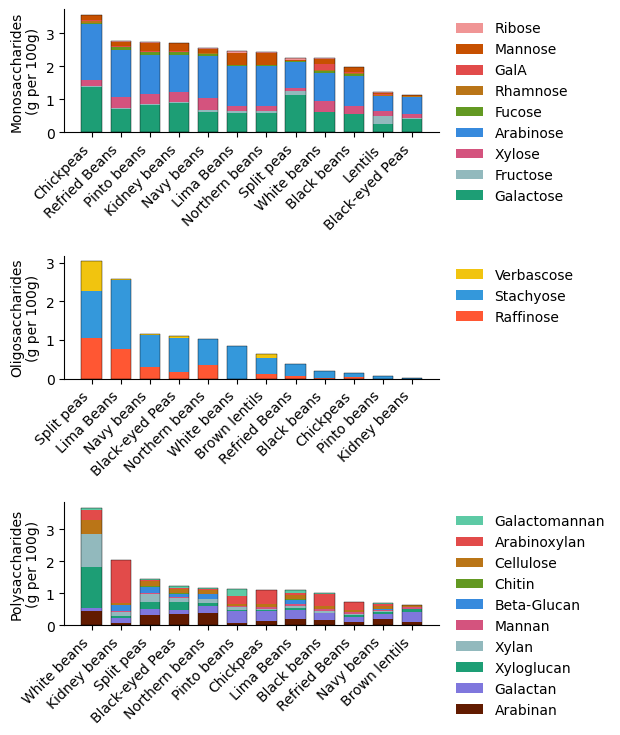

In [24]:
# Glycan columns to plot
mono_cols = [
    'Galactose',	'Fructose',	'Xylose',	'Arabinose',	'Fucose',	'Rhamnose',	'GalA',	'Mannose',	'Ribose'
]

mono_grouped = mono_pulse.set_index('simple_name')[mono_cols]
mono_grouped = mono_grouped.loc[mono_grouped.sum(axis=1).sort_values(ascending=False).index]
mono_grouped.reset_index(inplace=True)

# Color palette — mono
mono_colors = [
    '#1D9E75', '#92B9BD', '#D4537E', '#378ADD',
    '#639922', '#BA7517', '#E24B4A', '#C75000', '#F09595'
]

# Glycan columns to plot
free_cols = ['Raffinose',	'Stachyose',	'Verbascose'
]

free_grouped = free_pulse.set_index('simple_name')[free_cols]
free_grouped = free_grouped.loc[free_grouped.sum(axis=1).sort_values(ascending=False).index]
free_grouped.reset_index(inplace=True)

# Color palette — oligo
free_colors = [
    "#FF5733",  
    "#3498DB",  
    "#F1C40F", 
    "#E91E63",  
    "#1ABC9C",  
    "#FF6B35",  
    "#34495E",  
    "#E74C3C",  
    "#27AE60",  
    "#8E44AD",  
    "#2ECC71",  
    "#E24B4A",  
    "#F39C12",  
]
poly_cols = [
    'Arabinan', 'Galactan', 'Xyloglucan', 'Xylan', 'Mannan',
    'Beta-Glucan', 'Chitin', 'Cellulose',
    'Arabinoxylan', 'Galactomannan'
]

poly_grouped = poly_pulse.set_index('simple_name')[poly_cols]
poly_grouped = poly_grouped.loc[poly_grouped.sum(axis=1).sort_values(ascending=False).index]
poly_grouped.reset_index(inplace=True)

# Color palette -poly
poly_colors = [
    '#621B00', '#7F77DD', '#1D9E75', '#92B9BD', '#D4537E', '#378ADD',
    '#639922', '#BA7517', '#E24B4A', '#5DCAA5', '#F09595'
]


# panel config
panels = [
    dict(
        grouped  = mono_grouped,
        cols     = mono_cols,
        colors   = mono_colors,
        ylabel   = 'Monosaccharides\n(g per 100g)',
        title    = '',
    ),
    dict(
        grouped  = free_grouped,
        cols     = free_cols,
        colors   = free_colors,
        ylabel   = 'Oligosaccharides\n(g per 100g)',
        title    = '',
    ),
    dict(
        grouped  = poly_grouped,
        cols     = poly_cols,
        colors   = poly_colors,
        ylabel   = 'Polysaccharides\n(g per 100g)',
        title    = '',
    ),
]

# figure layout
fig, axes = plt.subplots(
    nrows=3, ncols=1,
    figsize=(6, 8),
    constrained_layout=False,
)

for ax, panel in zip(axes, panels):
    grouped = panel['grouped']
    cols    = panel['cols']
    colors  = panel['colors']

    x      = range(len(grouped))
    bottom = [0] * len(grouped)

    for i, col in enumerate(cols):
            ax.bar(x, grouped[col], bottom=bottom,
                   color=colors[i], label=col, width=0.7)
            bottom = [b + v for b, v in zip(bottom, grouped[col])]

    # Draw outline around the full stacked bar only
    ax.bar(x, bottom, bottom=0,
           color='none', edgecolor='black', linewidth=0.3, width=0.7)

    # x-axis — use the simple_name column, not the integer index
    ax.set_xticks(list(x))
    ax.set_xticklabels(grouped['simple_name'], rotation=45, ha='right', fontsize=10)
    
    # labels & spines
    ax.set_ylabel(panel['ylabel'], fontsize=10)
    ax.set_xlabel('', fontsize=10)
    ax.set_title(panel['title'], fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # legend to the right of each panel
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(
        handles[::-1], labels[::-1],
        bbox_to_anchor=(1.01, 1), loc='upper left',
        frameon=False, fontsize=10,
    )

plt.subplots_adjust(hspace=1, right=0.75)   # room for legends + row spacing
plt.savefig('../../plot/figure2a-c.png', dpi=300, bbox_inches='tight')
plt.show()

### visualize food group level intake of glycans (consumer means) & create a table of total glycan intake, pulse glycan intake, and percentage of pulse glycan intake relative to total

In [25]:
# load in the full cohort glycan intake
glycan_diet = pd.read_csv('../../data/01/all/nhanes_dfg2_ingredient_kcal_adjusted.csv', low_memory=False)

# load in the DFG2 database for foods that map to 24-hr recalls in the dataset
dfg2 = pd.read_csv('../../data/00/wweia_dataset/nhanes_dfg2_matched.csv')

In [26]:
# correct the food group designations for two entries in DFG2:
dfg2.loc[dfg2['simple_name'] == 'canned pumpkin', 'food_group'] = 'Vegetables'
dfg2.loc[dfg2['simple_name'] == 'Bean Sprouts', 'food_group'] = 'Vegetables'

dfg2.loc[dfg2['simple_name'] == 'Steamed whole snow peas', 'food_group'] = 'Vegetables'
dfg2.loc[dfg2['simple_name'] == 'Frozen Whole Sweet Green Peas (Flav R Pac)', 'food_group'] = 'Vegetables'

# rename categories to reflect splitting pulses into its own group. also consolidate eggs with meat category (protein foods) 
dfg2['food_group'] = dfg2['food_group'].replace('Beans, Peas, Legumes, Nuts, Seeds', 'Nuts, Seeds, Soy')
dfg2['food_group'] = dfg2['food_group'].replace('pulse', 'Beans, Peas, Lentils (Pulses)')
dfg2['food_group'] = dfg2['food_group'].replace('Grain Products', 'Grains')
dfg2['food_group'] = dfg2['food_group'].replace('Grain Products', 'Grains')
dfg2['food_group'] = dfg2['food_group'].replace('Meat, Poultry, Fish, and Mixtures', 'Meat, Poultry, Fish, Eggs') # consolidate meat and eggs
dfg2['food_group'] = dfg2['food_group'].replace('Eggs', 'Meat, Poultry, Fish, Eggs') # consolidate meat and eggs
dfg2['food_group'] = dfg2['food_group'].replace('Milk and Milk Products', 'Dairy')
dfg2['food_group'] = dfg2['food_group'].replace('Fats, Oils, and Salad Dressings', 'Dairy') # there is only one DFG2 entry for Fats, Oils, and Salad Dressings which is butter, this is reclassified under dairy
dfg2['food_group'] = dfg2['food_group'].replace('Sugars, Sweets, and Beverages', 'Sugars, Sweets, Beverages')

# dedup the mapping file to give unique set of foods in the database that appear in the diet
dfg2_unique = dfg2.drop_duplicates(subset='simple_name')

In [27]:
# correct the food group designations for entries in DFG2:
glycan_diet.loc[glycan_diet['simple_name'] == 'canned pumpkin', 'food_group'] = 'Vegetables'
glycan_diet.loc[glycan_diet['simple_name'] == 'Bean Sprouts', 'food_group'] = 'Vegetables'

glycan_diet.loc[glycan_diet['simple_name'] == 'Steamed whole snow peas', 'food_group'] = 'Vegetables'
glycan_diet.loc[glycan_diet['simple_name'] == 'Frozen Whole Sweet Green Peas (Flav R Pac)', 'food_group'] = 'Vegetables'

# rename categories to reflect splitting pulses into its own group. also consolidate eggs with meat category (protein foods) 
glycan_diet['food_group'] = glycan_diet['food_group'].replace('Beans, Peas, Legumes, Nuts, Seeds', 'Nuts, Seeds, Soy')
glycan_diet['food_group'] = glycan_diet['food_group'].replace('pulse', 'Beans, Peas, Lentils (Pulses)')
glycan_diet['food_group'] = glycan_diet['food_group'].replace('Grain Products', 'Grains')
glycan_diet['food_group'] = glycan_diet['food_group'].replace('Grain Products', 'Grains')
glycan_diet['food_group'] = glycan_diet['food_group'].replace('Meat, Poultry, Fish, and Mixtures', 'Meat, Poultry, Fish, Eggs') # consolidate meat and eggs
glycan_diet['food_group'] = glycan_diet['food_group'].replace('Eggs', 'Meat, Poultry, Fish, Eggs') # consolidate meat and eggs
glycan_diet['food_group'] = glycan_diet['food_group'].replace('Milk and Milk Products', 'Dairy')
glycan_diet['food_group'] = glycan_diet['food_group'].replace('Fats, Oils, and Salad Dressings', 'Dairy') # there is only one DFG2 entry for Fats, Oils, and Salad Dressings which is butter, this is reclassified under dairy
glycan_diet['food_group'] = glycan_diet['food_group'].replace('Sugars, Sweets, and Beverages', 'Sugars, Sweets, Beverages')


## food group glycan heatmap

In [28]:
# Create a mapping dictionary for the renaming
rename_dict = {
    'Free_Kestose': 'Kestose',
    'Free_Raffinose': 'Raffinose',
    'Free_Maltotetraose': 'Maltotetraose',
    'Free_Stachyose': 'Stachyose',
    'Free_Maltopentaose': 'Maltopentaose',
    'Free_Verbascose': 'Verbascose',
    'Free_Maltohexaose': 'Maltohexaose',
    'Mono_Galactose': 'Galactose',
    'Mono_Fructose': 'Fructose',
    'Mono_Xylose': 'Xylose',
    'Mono_Arabinose': 'Arabinose',
    'Mono_Fucose': 'Fucose',
    'Mono_Rhamnose': 'Rhamnose',
    'Mono_GalA': 'GalA',
    'Mono_Mannose': 'Mannose',
    'Mono_Ribose': 'Ribose'
}

# Rename the columns
glycan_diet = glycan_diet.rename(columns=rename_dict)

# Define glycan types
polysaccharides = ['Arabinan', 'Galactan', 'Xyloglucan', 'Xylan', 'Mannan',
                   'Beta-Glucan', 'Chitin', 'Cellulose', 'Arabinoxylan',
                   'Galactomannan']

oligosaccharides = ['Kestose', 'Raffinose', 'Maltotetraose', 'Stachyose',
                    'Maltopentaose', 'Verbascose', 'Maltohexaose']

monosaccharides = ['Galactose', 'Xylose', 'Arabinose', 'Fucose', 
                   'Rhamnose', 'GalA', 'Mannose', 'Ribose']

digesitble_sugars = ['Free_Lactose(trehalose)', 'Free_Maltose', 'Starch', 'Free_Fructose', 'Free_Glucose', 'Free_Sucrose', 'Mono_Glucose']

all_glycans = polysaccharides + oligosaccharides + monosaccharides

In [29]:
# Step 1: Sum all glycan intake per person per food group
person_foodgroup_glycans = glycan_diet.groupby(['SEQN', 'food_group'])[all_glycans].sum().reset_index()

# Step 2: Average across people
glycan_foodgroup_matrix = person_foodgroup_glycans.groupby('food_group')[all_glycans].mean().reset_index()

# Sort by total glycan content
glycan_foodgroup_matrix['total'] = glycan_foodgroup_matrix[all_glycans].sum(axis=1)
glycan_foodgroup_matrix = glycan_foodgroup_matrix.sort_values('total', ascending=False).drop('total', axis=1)

/var/folders/cn/jmx8y74x39z_w2hldtxvcgch0000gn/T/ipykernel_15220/2058392142.py:57: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


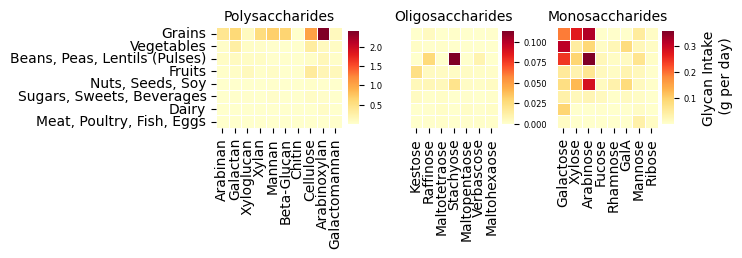

In [30]:
# Prepare data
food_groups = glycan_foodgroup_matrix['food_group'].values

# Calculate width ratios based on number of glycans in each category
width_ratios = [len(polysaccharides), len(oligosaccharides), len(monosaccharides)]

# Create figure with proportional widths
fig = plt.figure(figsize=(6, 4))
gs = GridSpec(1, 3, width_ratios=width_ratios, wspace=0.3)

axes = [fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])]

glycan_types = [
    (polysaccharides, 'Polysaccharides', axes[0]),
    (oligosaccharides, 'Oligosaccharides', axes[1]),
    (monosaccharides, 'Monosaccharides', axes[2])
]

for i, (glycan_list, title, ax) in enumerate(glycan_types):
    data = glycan_foodgroup_matrix[glycan_list].values
    
    im = sns.heatmap(data,
                xticklabels=glycan_list,
                yticklabels=food_groups if i == 0 else False,  # Only first plot
                cmap='YlOrRd',
                cbar_kws={
                    'label': '',
                    'shrink': 0.3,
                    'aspect': 8,
                    'pad': 0.04
                },
                ax=ax,
                linewidths=0.5,
                linecolor='white',
                square=True)
    
    # Scale down colorbar text
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=6)
    cbar.set_label('Glycan Intake\n (g per day)', fontsize=10) if i == 2 else None
    
    ax.set_title(title, fontsize=10, pad=5)
    ax.set_xlabel('', fontsize=10)
    ax.tick_params(axis='x', rotation=90, labelsize=10)
    
    # Only show y-label and y-ticks on first plot
    if i == 0:
        ax.set_ylabel('', fontsize=10)
        ax.tick_params(axis='y', labelsize=10, rotation=0)
    else:
        ax.set_ylabel('')
        ax.tick_params(axis='y', labelsize=10, left=False)  # Remove ticks

plt.suptitle('', 
             fontsize=10, y=0.98)

plt.tight_layout()
plt.savefig('../../plot/figure2d.png', dpi=300, bbox_inches='tight')
plt.show()

In [31]:
# Get the sum of each glycan column across all food groups
glycan_totals = glycan_foodgroup_matrix.drop('food_group', axis=1).sum()

# Get the values for "Beans, Peas, Lentils (Pulses)"
pulses_row = glycan_foodgroup_matrix[glycan_foodgroup_matrix['food_group'] == 'Beans, Peas, Lentils (Pulses)'].drop('food_group', axis=1)

# Calculate the percentage contribution for each glycan
pulses_percentage = (pulses_row.values[0] / glycan_totals.values) * 100

# Create a dataframe to view the results
import pandas as pd
results = pd.DataFrame({
    'Glycan': glycan_totals.index,
    'Total': glycan_totals.values,
    'Pulses_Amount': pulses_row.values[0],
    'Pulses_Percentage': pulses_percentage
})

results['Total'] = results['Total'] * 1000
results['Pulses_Amount'] = results['Pulses_Amount'] * 1000

In [32]:
# save results table
results.sort_values(by='Pulses_Percentage', ascending=False).round(1).to_csv('../../output/table_s1.csv', index=None)